## Additional BST Diagnostics

This notebook is intentionally limited to analyses not already covered by the BST notebook:
1. Active (last interaction within 7 days) versus inactive sessions.
2. Common versus one-off queries.
3. Exposure distribution by product-popularity bucket.
4. Representative ranking failures for BST and LightGBM.

## 0. Setup and project paths

In [ ]:
from google.colab import drive
try:
    drive.mount('/content/drive', force_remount=True)
except Exception as e:
    print("Drive mount error or already mounted:", e)

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import re
from IPython.display import display

# Dynamically search for the base path if the default Final path does not exist
possible_paths = [
    Path("/content/drive/MyDrive/BT4222 Final/JDSearch"),
    Path("/content/drive/MyDrive/JDSearch"),
    Path("/content/drive/Shareddrives/BT4222 Final/JDSearch"),
    Path("/content/drive/My Drive/BT4222 Final/JDSearch")
]

BASE = possible_paths[0]
for p in possible_paths:
    if p.exists():
        BASE = p
        break

print("BASE directory:", BASE)

BST_PRED_PATH = BASE / "processed/bst_literal/test_predictions.parquet"
LGBM_PRED_PATH = BASE / "model_artifacts/lightgbm_popularity_query_search/full/test_predictions.parquet"
LGBM_TEST_FEATURES_PATH = BASE / "processed/lgbm_features_all/test.parquet"

# Fallback searching if the explicit file structures are missing
if not BST_PRED_PATH.exists():
    print("Warning: BST file not found at default path. Performing fallback file locating...")
    for root, dirs, files in os.walk('/content/drive/MyDrive/'):
        if 'test_predictions.parquet' in files and 'bst_literal' in root:
            BST_PRED_PATH = Path(root) / 'test_predictions.parquet'
            BASE = Path(root).parents[1]
            print("Dynamically found valid directory at:", BASE)
            break

print("BASE exists:", BASE.exists())
print("BST predictions path:", BST_PRED_PATH, "(exists: ", BST_PRED_PATH.exists(), ")")
print("LGBM predictions path:", LGBM_PRED_PATH, "(exists: ", LGBM_PRED_PATH.exists(), ")")
print("LGBM features path:", LGBM_TEST_FEATURES_PATH, "(exists: ", LGBM_TEST_FEATURES_PATH.exists(), ")")

Mounted at /content/drive
BASE directory: /content/drive/MyDrive/BT4222 Final/JDSearch
BASE exists: True
BST predictions path: /content/drive/MyDrive/BT4222 Final/JDSearch/processed/bst_literal/test_predictions.parquet (exists:  True )
LGBM predictions path: /content/drive/MyDrive/BT4222 Final/JDSearch/model_artifacts/lightgbm_popularity_query_search/full/test_predictions.parquet (exists:  True )
LGBM features path: /content/drive/MyDrive/BT4222 Final/JDSearch/processed/lgbm_features_all/test.parquet (exists:  True )


## 1. Load predictions and inspect schemas

This step does not assume that the two prediction files have identical schemas. It prints the available columns and samples so the correct join keys can be confirmed.

In [ ]:
bst = pd.read_parquet(BST_PRED_PATH)
lgbm = pd.read_parquet(LGBM_PRED_PATH)
features = pd.read_parquet(LGBM_TEST_FEATURES_PATH)

for name, df in [("BST predictions", bst), ("LightGBM predictions", lgbm), ("LightGBM test features", features)]:
    print(f"\n{name}: shape={df.shape}")
    print("columns:", df.columns.tolist())
    display(df.head(3))


BST predictions: shape=(1531525, 4)
columns: ['session_id', 'wid', 'label', 'score']


,session_id,wid,label,score
0,22,85130925,0,-3.884766
1,22,50512553,0,-3.884766
2,22,52977511,0,-3.890625



LightGBM predictions: shape=(1531525, 4)
columns: ['session_id', 'wid', 'label', 'score']


,session_id,wid,label,score
0,22,85130925,0,-1.562659
1,22,50512553,0,-1.566192
2,22,52977511,0,-1.562212



LightGBM test features: shape=(1531525, 93)
columns: ['session_id', 'wid', 'label', 'exact_wid_click_0_7d', 'exact_wid_cart_0_7d', 'exact_wid_ord_0_7d', 'exact_wid_cart_7_90d', 'exact_wid_ord_7_90d', 'exact_wid_ord_90_365d', 'exact_wid_last_seen_days', 'brand_aff', 'brand_share', 'brand_last_seen_days', 'brand_ord_cnt', 'shop_aff', 'shop_share', 'shop_last_seen_days', 'shop_ord_cnt', 'cate1_aff', 'cate1_share', 'cate1_last_seen_days', 'cate1_ord_cnt', 'cate2_aff', 'cate2_share', 'cate2_last_seen_days', 'cate2_ord_cnt', 'cate3_aff', 'cate3_share', 'cate3_last_seen_days', 'cate3_ord_cnt', 'cate4_aff', 'cate4_share', 'cate4_last_seen_days', 'cate4_ord_cnt', 'title_cos_profile', 'title_cos_profile_ord', 'title_cos_max', 'title_hist_qry_overlap', 'i2v_cos_mean', 'i2v_cos_max', 'i2v_cos_last5', 't2v_cos_profile', 'last_same_brand', 'last_same_cate3', 'last_title_cos', 'last_i2v_cos', 'qhist_n_actions', 'qhist_wid_cnt', 'qhist_brand_aff', 'qhist_cate3_aff', 'item_ctr_train', 'brand_ctr_train

,session_id,wid,label,exact_wid_click_0_7d,exact_wid_cart_0_7d,exact_wid_ord_0_7d,exact_wid_cart_7_90d,exact_wid_ord_7_90d,exact_wid_ord_90_365d,exact_wid_last_seen_days,...,history_span_days,days_since_last_interaction,share_click,share_cart,share_ord,share_flw,cate3_entropy,n_distinct_brands,qryless_share,burst_len
0,22,85130925,0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,...,359.965881,0.546736,0.073171,0.195122,0.731707,0.0,3.807022,57.0,0.365854,8.0
1,22,50512553,0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,...,359.965881,0.546736,0.073171,0.195122,0.731707,0.0,3.807022,57.0,0.365854,8.0
2,22,52977511,0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,...,359.965881,0.546736,0.073171,0.195122,0.731707,0.0,3.807022,57.0,0.365854,8.0


In [ ]:
# 1. Inspect Ningjing's feature table for item_pop_train
ningjing_path = BASE / "processed/ningjing_test_features_with_baselines.parquet"
if ningjing_path.exists():
    ningjing_features = pd.read_parquet(ningjing_path)
    print("Ningjing Features columns matching 'pop' or 'id':", [c for c in ningjing_features.columns if 'pop' in c.lower() or 'id' in c.lower()])
    display(ningjing_features[['session_id', 'item_id', 'item_pop_train']].head(5))
else:
    print("Ningjing features file not found.")

Ningjing Features columns matching 'pop' or 'id': ['session_id', 'item_id', 'item_pop_train', 'brand_pop_train', 'cate4_pop_train', 'cate_id_1', 'cate_id_2', 'cate_id_3', 'cate_id_4', 'hybrid_score', 'ncf_hybrid_score']


,session_id,item_id,item_pop_train
0,22,85332275,0.0
1,22,9588170,0.0
2,22,90234132,0.0
3,22,32266824,0.0
4,22,52977511,0.0


In [ ]:
# 2. Verify if days_since_last_interaction is consistent within each session
recency_check = features.groupby("session_id")["days_since_last_interaction"].nunique(dropna=False)
print("Sessions with inconsistent recency values (should be 0):", (recency_check > 1).sum())
print("Sessions with missing recency:", features.groupby("session_id")["days_since_last_interaction"].first().isna().sum())

Sessions with inconsistent recency values (should be 0): 0
Sessions with missing recency: 0


In [ ]:
# Load and inspect session queries parquet file
queries_df = pd.read_parquet(BASE / "model_artifacts/lightgbm_popularity_query_search/cached_merged_features/session_queries.parquet")
print("Session Queries shape:", queries_df.shape)
print("Columns:", queries_df.columns.tolist())
display(queries_df.head(5))

Session Queries shape: (173831, 2)
Columns: ['session_id', 'query']


,session_id,query
0,0,63995226602574196100244625575117
1,1,1254963427438884
2,2,24374376067768939206305
3,3,29463948632095349356845164880503931105432...
4,4,2793914964365783663289


In [ ]:
# 3. Verify test sessions and query coverage
test_sessions = set(bst["session_id"].unique())
query_sessions = set(queries_df["session_id"].unique())
print("Prediction sessions in BST:", len(test_sessions))
print("Sessions with query:", len(test_sessions & query_sessions))
print("Sessions missing query:", len(test_sessions - query_sessions))

Prediction sessions in BST: 17118
Sessions with query: 17118
Sessions missing query: 0


In [ ]:
# Search the base directory for any other files that might contain query or session details.
if BASE.exists():
    for root, dirs, files in os.walk(BASE):
        for file in files:
            if any(k in file.lower() for k in ['session', 'query', 'user', 'test', 'meta']):
                print(os.path.join(root, file))


/content/drive/MyDrive/BT4222 Final/JDSearch/Raw Data/product_meta_data.txt
/content/drive/MyDrive/BT4222 Final/JDSearch/Raw Data/user_behavior_data.txt
/content/drive/MyDrive/BT4222 Final/JDSearch/model_artifacts/lightgbm_popularity_query_search/full/test_predictions.parquet
/content/drive/MyDrive/BT4222 Final/JDSearch/model_artifacts/lightgbm_popularity_query_search/full/test_groups.npy
/content/drive/MyDrive/BT4222 Final/JDSearch/model_artifacts/lightgbm_popularity_query_search/cached_merged_features/session_queries.parquet
/content/drive/MyDrive/BT4222 Final/JDSearch/model_artifacts/lightgbm_popularity_query_search/cached_merged_features/selected_features/test.parquet
/content/drive/MyDrive/BT4222 Final/JDSearch/model_artifacts/lightgbm_popularity_query_search/cached_merged_features/selected_features/test_groups.npy
/content/drive/MyDrive/BT4222 Final/JDSearch/model_artifacts/4B_results/nmf_ncf_scores_test.parquet
/content/drive/MyDrive/BT4222 Final/JDSearch/model_artifacts/Truman_

In [ ]:
# Search the feature dataframe for possible matches for query, session time, and product popularity.
for col in features.columns:
    if any(keyword in col.lower() for keyword in ['query', 'q_', 'time', 'date', 'pop', 'impr', 'day']):
        print(f"{col}: {features[col].dtype} (nulls: {features[col].isna().mean():.2%})")

# Inspect some samples of candidate date/time or click history features to locate our proxy metrics.
display(features[['days_since_last_interaction', 'item_impr_train', 'history_len_clean', 'history_span_days']].head())


exact_wid_last_seen_days: float32 (nulls: 99.19%)
brand_last_seen_days: float32 (nulls: 77.99%)
shop_last_seen_days: float32 (nulls: 93.05%)
cate1_last_seen_days: float32 (nulls: 25.13%)
cate2_last_seen_days: float32 (nulls: 42.91%)
cate3_last_seen_days: float32 (nulls: 59.77%)
cate4_last_seen_days: float32 (nulls: 62.66%)
item_impr_train: float32 (nulls: 0.00%)
history_span_days: float32 (nulls: 0.00%)
days_since_last_interaction: float32 (nulls: 0.00%)


,days_since_last_interaction,item_impr_train,history_len_clean,history_span_days
0,0.546736,0.693147,82.0,359.965881
1,0.546736,0.693147,82.0,359.965881
2,0.546736,0.693147,82.0,359.965881
3,0.546736,0.693147,82.0,359.965881
4,0.546736,0.693147,82.0,359.965881


## 2. Configure columns only after inspecting the outputs

For the remaining analyses, identify:
- the session-level search query column;
- the timestamp/date of the search session;
- the timestamp/date of the user's most recent interaction before that session;
- the candidate-level popularity bucket or `item_pop_train` value.

If the latest interaction date is not available as a session-level field, derive it from the historical interaction table using only interactions that occurred before the search timestamp. Do not use future interactions.

In [ ]:
SESSION_COL = "session_id"
ITEM_COL = "wid"
LABEL_COL = "label"
BST_SCORE_COL = "score"
LGBM_SCORE_COL = "score"

QUERY_COL = "query"
SESSION_TIME_COL = "session_time_placeholder"
LAST_INTERACTION_TIME_COL = "last_interaction_placeholder"
ITEM_POP_COL = "item_pop_train"

COMMON_QUERY_MIN_SESSIONS = 2

# Verify required prediction columns
required_pred = {SESSION_COL, ITEM_COL, LABEL_COL}
for name, df in [("BST", bst), ("LightGBM", lgbm)]:
    missing = required_pred - set(df.columns)
    if missing:
        raise ValueError(f"{name} predictions missing columns: {missing}")
    print(name, "rows:", len(df), "sessions:", df[SESSION_COL].nunique())

# Load the queries mapping into a global session_table variable to use downstream
session_table = queries_df


BST rows: 1531525 sessions: 17118
LightGBM rows: 1531525 sessions: 17118


## 3. Active versus inactive sessions

Active means the user's most recent recorded interaction before the search occurred within the preceding seven days.

Inactive means more than seven days.

In [ ]:
def add_activity_group(df):
    # Since we have pre-computed days_since_last_interaction directly in the features dataframe,
    # we will extract it and map it to session activity groups.
    out = df.copy()

    # If df is candidate level, map each session's minimum or first days_since_last_interaction
    if "days_since_last_interaction" not in out.columns and "session_id" in out.columns:
        recency_map = features.groupby("session_id")["days_since_last_interaction"].first()
        out["days_since_last_interaction"] = out["session_id"].map(recency_map)

    out["activity_group"] = np.where(
        out["days_since_last_interaction"].le(7), "Active (<=7 days)", "Inactive (>7 days)"
    )
    out.loc[out["days_since_last_interaction"].isna(), "activity_group"] = np.nan
    return out


Summarise ranking performance by activity group

This uses binary NDCG@10, MRR and P@1 for a transparent standalone diagnostic.

In [ ]:
def session_metrics(pred, score_col, session_col=SESSION_COL, label_col=LABEL_COL, k=10):
    # Optimize to run efficiently
    sorted_pred = pred.sort_values([session_col, score_col], ascending=[True, False])

    # Precompute positions for NDCG
    discounts = 1 / np.log2(np.arange(2, k + 2))

    rows = []
    for sid, g in sorted_pred.groupby(session_col, sort=False):
        rel = (g[label_col].to_numpy() > 0).astype(int)
        top = rel[:k]

        # DCG
        dcg = float((top * discounts[:len(top)]).sum())

        # IDCG
        ideal = np.sort(rel)[::-1][:k]
        idcg = float((ideal * discounts[:len(ideal)]).sum())

        ndcg = dcg / idcg if idcg > 0 else np.nan

        # MRR
        hit_ranks = np.flatnonzero(rel > 0)
        mrr = 1 / (hit_ranks[0] + 1) if len(hit_ranks) else 0.0

        # P@1
        p1 = float(rel[0]) if len(rel) else 0.0

        rows.append((sid, ndcg, mrr, p1))

    return pd.DataFrame(rows, columns=[session_col, "NDCG@10", "MRR", "P@1"])

def compare_by_group(pred, score_col, session_groups):
    m = session_metrics(pred, score_col)
    z = m.merge(session_groups[[SESSION_COL, "activity_group"]].drop_duplicates(), on=SESSION_COL, how="inner")
    return z.groupby("activity_group").agg(
        sessions=(SESSION_COL, "nunique"),
        ndcg_mean=("NDCG@10", "mean"),
        mrr_mean=("MRR", "mean"),
        p1_mean=("P@1", "mean")
    ).reset_index()

# Prepare session context using our modified activity extractor
session_context = bst[[SESSION_COL]].drop_duplicates()
session_context = add_activity_group(session_context)

print("=== BST Ranking Performance by Activity Group ===")
bst_activity_results = compare_by_group(bst, BST_SCORE_COL, session_context)
display(bst_activity_results)

print("=== LightGBM Ranking Performance by Activity Group ===")
lgbm_activity_results = compare_by_group(lgbm, LGBM_SCORE_COL, session_context)
display(lgbm_activity_results)


=== BST Ranking Performance by Activity Group ===


,activity_group,sessions,ndcg_mean,mrr_mean,p1_mean
0,Active (<=7 days),15167,0.394228,0.399044,0.262478
1,Inactive (>7 days),1951,0.353758,0.357074,0.220400


=== LightGBM Ranking Performance by Activity Group ===


,activity_group,sessions,ndcg_mean,mrr_mean,p1_mean
0,Active (<=7 days),15167,0.414758,0.417490,0.277774
1,Inactive (>7 days),1951,0.375244,0.370009,0.224500


In [ ]:
# --------------------------------------------------
# Short vs Long User History
# --------------------------------------------------

# Check that history length is consistent within each session
history_check = (
    features.groupby(SESSION_COL)["history_len_clean"]
    .nunique(dropna=False)
)

print(
    "Sessions with inconsistent history length:",
    (history_check > 1).sum()
)

# Build one row per session
history_context = (
    features.groupby(SESSION_COL)["history_len_clean"]
    .first()
    .reset_index()
)

# Check for missing history values
print(
    "Sessions with missing history length:",
    history_context["history_len_clean"].isna().sum()
)

# Calculate median history length across test sessions
history_median = history_context["history_len_clean"].median()

print("Median history length:", history_median)

# Divide sessions into two groups
history_context["history_group"] = np.where(
    history_context["history_len_clean"] <= history_median,
    "Short history (<= median)",
    "Long history (> median)"
)

display(
    history_context["history_group"].value_counts().reset_index()
)

Sessions with inconsistent history length: 0
Sessions with missing history length: 0
Median history length: 78.0


,history_group,count
0,Short history (<= median),8579
1,Long history (> median),8539


In [ ]:
# --------------------------------------------------
# Compare BST and LightGBM by history length
# --------------------------------------------------

def compare_by_history(pred, score_col, session_groups):

    metrics = session_metrics(pred, score_col)

    merged = metrics.merge(
        session_groups[
            [SESSION_COL, "history_group"]
        ],
        on=SESSION_COL,
        how="inner"
    )

    return (
        merged.groupby("history_group")
        .agg(
            sessions=(SESSION_COL, "nunique"),
            binary_ndcg_mean=("NDCG@10", "mean"),
            mrr_mean=("MRR", "mean"),
            p1_mean=("P@1", "mean")
        )
        .reset_index()
    )


bst_history_results = compare_by_history(
    bst,
    BST_SCORE_COL,
    history_context
)

lgbm_history_results = compare_by_history(
    lgbm,
    LGBM_SCORE_COL,
    history_context
)

print("=== BST Performance by History Length ===")
display(bst_history_results)

print("=== LightGBM Performance by History Length ===")
display(lgbm_history_results)

=== BST Performance by History Length ===


,history_group,sessions,binary_ndcg_mean,mrr_mean,p1_mean
0,Long history (> median),8539,0.394540,0.397795,0.259047
1,Short history (<= median),8579,0.384714,0.390743,0.256324


=== LightGBM Performance by History Length ===


,history_group,sessions,binary_ndcg_mean,mrr_mean,p1_mean
0,Long history (> median),8539,0.415157,0.416857,0.274271
1,Short history (<= median),8579,0.405374,0.407323,0.269146


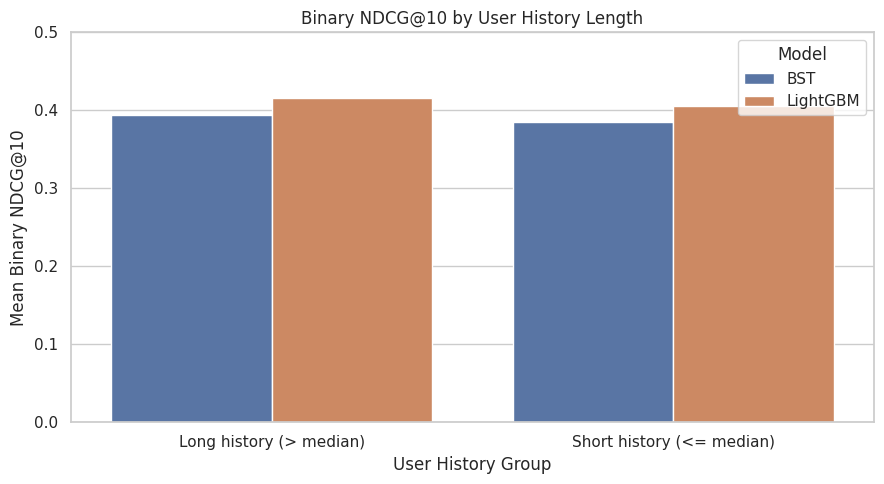

In [ ]:
history_plot = pd.concat([
    bst_history_results.assign(Model="BST"),
    lgbm_history_results.assign(Model="LightGBM")
], ignore_index=True)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=history_plot,
    x="history_group",
    y="binary_ndcg_mean",
    hue="Model"
)

plt.title("Binary NDCG@10 by User History Length")
plt.xlabel("User History Group")
plt.ylabel("Mean Binary NDCG@10")
plt.ylim(0, 0.5)

plt.tight_layout()
plt.show()

These results show that both models perform slightly better for long-history users and the LightGBM model performs slightly better than the BST model across all user groups.

## 4. Common versus one-off queries

Queries are normalised by lowercasing, trimming whitespace and collapsing repeated whitespace.
- Common: the normalised query appears in at least two distinct test sessions.
- One-off: it appears in exactly one distinct test session.

This is a descriptive test-set grouping, not a model feature.

In [ ]:

# --------------------------------------------------
# Common vs One-off Queries (TEST SET ONLY)
# --------------------------------------------------

def normalise_query(value):
    if pd.isna(value):
        return np.nan
    return re.sub(r"\s+", " ", str(value).strip().lower())


def make_query_groups(session_table, test_sessions):
    if QUERY_COL is None:
        raise ValueError("Set QUERY_COL after inspecting the session/query table.")

    # Keep only sessions appearing in the BST test predictions
    q = session_table[
        session_table[SESSION_COL].isin(test_sessions)
    ][[SESSION_COL, QUERY_COL]].copy()

    # Ensure one query per session
    q = q.drop_duplicates(subset=[SESSION_COL])

    # Normalise query text
    q["normalised_query"] = q[QUERY_COL].map(normalise_query)

    # Count query frequency ONLY within the test set
    freq = (
        q.dropna(subset=["normalised_query"])
        .loc[lambda x: x["normalised_query"].ne("")]
        .groupby("normalised_query")[SESSION_COL]
        .nunique()
    )

    q["query_session_frequency"] = q["normalised_query"].map(freq)

    # Classify queries based on test-set frequency
    q["query_group"] = np.where(
        q["query_session_frequency"] >= COMMON_QUERY_MIN_SESSIONS,
        "Common query",
        "One-off query"
    )

    # Exclude missing or empty queries
    q.loc[
        q["normalised_query"].isna() | q["normalised_query"].eq(""),
        "query_group"
    ] = np.nan

    # Validation
    print("Test sessions:", len(test_sessions))
    print("Sessions with query:", q[SESSION_COL].nunique())
    print("Sessions missing query:", q["query_group"].isna().sum())

    return q


def compare_query_groups(pred, score_col, query_groups):

    metrics = session_metrics(pred, score_col)

    # Only compare sessions present in the test-set query groups
    z = metrics.merge(
        query_groups[[SESSION_COL, "query_group"]],
        on=SESSION_COL,
        how="inner"
    )

    return (
        z.groupby("query_group")
        .agg(
            sessions=(SESSION_COL, "nunique"),
            binary_ndcg_mean=("NDCG@10", "mean"),
            mrr_mean=("MRR", "mean"),
            p1_mean=("P@1", "mean")
        )
        .reset_index()
    )


# Generate test-set query groups
test_sessions = set(bst[SESSION_COL].unique())

query_groups = make_query_groups(
    session_table,
    test_sessions
)

print("=== BST Ranking Performance by Test-Set Query Frequency ===")
bst_query_results = compare_query_groups(
    bst,
    BST_SCORE_COL,
    query_groups
)
display(bst_query_results)

print("=== LightGBM Ranking Performance by Test-Set Query Frequency ===")
lgbm_query_results = compare_query_groups(
    lgbm,
    LGBM_SCORE_COL,
    query_groups
)
display(lgbm_query_results)

Test sessions: 17118
Sessions with query: 17118
Sessions missing query: 0
=== BST Ranking Performance by Test-Set Query Frequency ===


,query_group,sessions,binary_ndcg_mean,mrr_mean,p1_mean
0,Common query,3758,0.445250,0.443800,0.302555
1,One-off query,13360,0.373967,0.380326,0.245060


=== LightGBM Ranking Performance by Test-Set Query Frequency ===


,query_group,sessions,binary_ndcg_mean,mrr_mean,p1_mean
0,Common query,3758,0.460707,0.456681,0.313997
1,One-off query,13360,0.396063,0.399533,0.259805


In [ ]:
ningjing_df = pd.read_parquet(ningjing_path)

# Identify the exact session-product pairs in BST test predictions
test_candidate_pairs = bst[
    [SESSION_COL, ITEM_COL]
].drop_duplicates().copy()

# Prepare Ningjing's popularity mapping
pop_mapping = ningjing_df[
    ["session_id", "item_id", "item_pop_train"]
].copy()

pop_mapping = pop_mapping.rename(columns={
    "item_id": ITEM_COL
})

# Align data types before joining
for df in [test_candidate_pairs, pop_mapping]:
    df[SESSION_COL] = df[SESSION_COL].astype(np.int64)
    df[ITEM_COL] = df[ITEM_COL].astype(np.int64)

# Restrict popularity mapping to BST test candidates
pop_mapping = test_candidate_pairs.merge(
    pop_mapping.drop_duplicates([SESSION_COL, ITEM_COL]),
    on=[SESSION_COL, ITEM_COL],
    how="left"
)

# Check matching coverage
print("BST test candidate pairs:", len(test_candidate_pairs))
print("Popularity mapping rows:", len(pop_mapping))
print("Missing popularity values:", pop_mapping["item_pop_train"].isna().sum())

# Fill missing values only if the source table is confirmed to cover
# the same test candidates and missing means zero training engagement.
pop_mapping["item_pop_train"] = pop_mapping["item_pop_train"].fillna(0.0)

# Attach popularity to BST test predictions
bst_pop = bst.merge(
    pop_mapping,
    on=[SESSION_COL, ITEM_COL],
    how="left",
    validate="many_to_one"
)

print("BST test prediction rows:", len(bst))
print("BST popularity-joined rows:", len(bst_pop))

BST test candidate pairs: 1531525
Popularity mapping rows: 1531525
Missing popularity values: 0
BST test prediction rows: 1531525
BST popularity-joined rows: 1531525


In [ ]:
def make_popularity_buckets(df, pop_col=ITEM_POP_COL):
    out = df.copy()

    # Use the same fixed bucket definitions as Ningjing's analysis
    conditions = [
        out[pop_col].eq(0),
        out[pop_col].eq(1),
        out[pop_col].between(2, 5),
        out[pop_col].between(6, 20),
        out[pop_col].gt(20)
    ]

    labels = [
        "No training engagement",
        "Very low (1)",
        "Low (2-5)",
        "Medium (6-20)",
        "High (20+)"
    ]

    out["popularity_bucket"] = np.select(
        conditions,
        labels,
        default="Unknown"
    )

    return out


bst_pop_bucketed = make_popularity_buckets(
    bst_pop,
    pop_col=ITEM_POP_COL
)


# --------------------------------------------------
# Calculate candidate share vs Top-10 exposure share
# --------------------------------------------------

def exposure_table(pred_with_pop, score_col, k=10):

    ranked = pred_with_pop.sort_values(
        [SESSION_COL, score_col],
        ascending=[True, False]
    )

    ranked["rank"] = ranked.groupby(SESSION_COL).cumcount() + 1

    topk = ranked[ranked["rank"] <= k].copy()

    candidate_counts = (
        pred_with_pop.groupby("popularity_bucket")[ITEM_COL]
        .count()
    )

    exposure_counts = (
        topk.groupby("popularity_bucket")[ITEM_COL]
        .count()
    )

    result = pd.DataFrame({
        "candidate_rows": candidate_counts,
        "top10_slots": exposure_counts
    }).fillna(0)

    total_candidates = result["candidate_rows"].sum()
    total_exposure = result["top10_slots"].sum()

    result["candidate_share"] = (
        result["candidate_rows"] / total_candidates
        if total_candidates > 0 else 0
    )

    result["top10_exposure_share"] = (
        result["top10_slots"] / total_exposure
        if total_exposure > 0 else 0
    )

    # Maintain Ningjing's bucket ordering
    result = result.reindex([
    "No training engagement",
    "Very low (1)",
    "Low (2-5)",
    "Medium (6-20)",
    "High (20+)"
])

    return result.reset_index()


bst_exposure_results = exposure_table(
    bst_pop_bucketed,
    BST_SCORE_COL
)

display(bst_exposure_results)

,popularity_bucket,candidate_rows,top10_slots,candidate_share,top10_exposure_share
0,No training engagement,1370366,86441,0.894772,0.509405
1,Very low (1),87567,32738,0.057176,0.192928
2,Low (2-5),51424,31868,0.033577,0.187801
3,Medium (6-20),17373,14265,0.011344,0.084065
4,High (20+),4795,4378,0.003131,0.025800


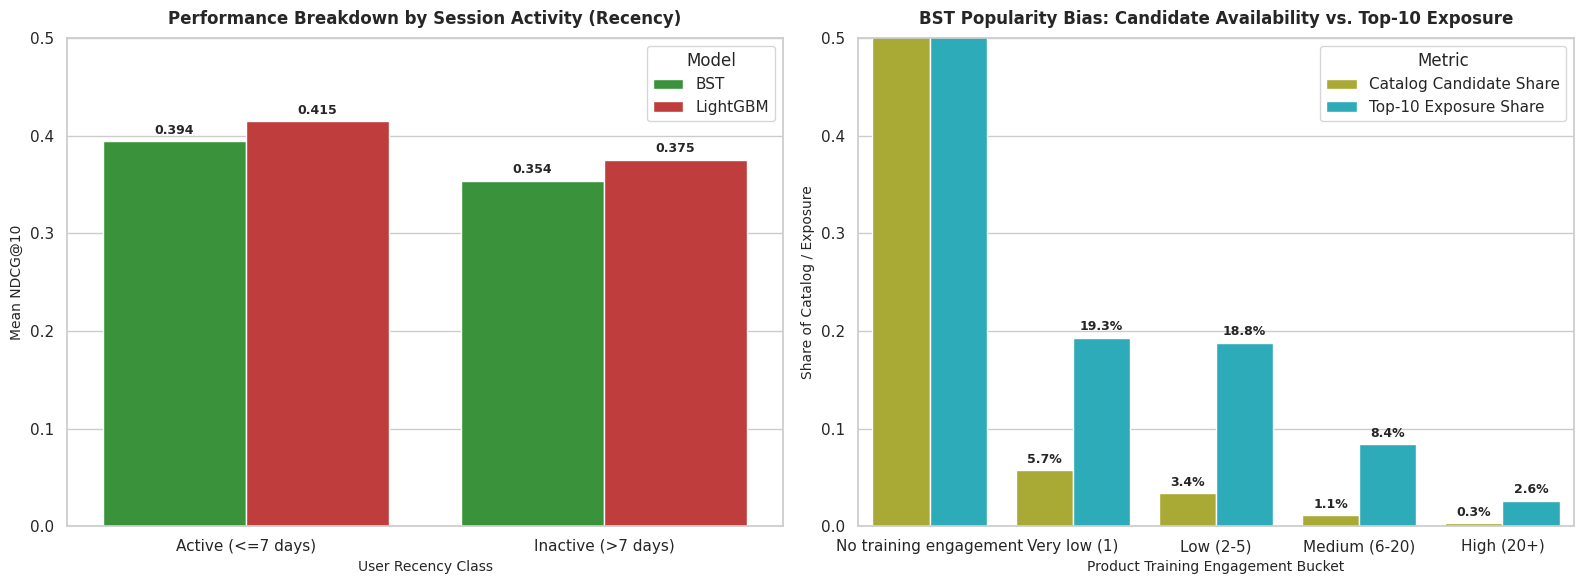

In [ ]:
# 1. Performance across User Activity Groups
bst_act = bst_activity_results[['activity_group', 'ndcg_mean']].copy()
bst_act['Model'] = 'BST'
lgbm_act = lgbm_activity_results[['activity_group', 'ndcg_mean']].copy()
lgbm_act['Model'] = 'LightGBM'

act_plot_df = pd.concat([bst_act, lgbm_act], ignore_index=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.set_theme(style="whitegrid")

# Subplot 1: Active vs Inactive NDCG@10
ax1 = sns.barplot(
    x="activity_group",
    y="ndcg_mean",
    hue="Model",
    data=act_plot_df,
    palette=["#2ca02c", "#d62728"],
    ax=axes[0]
)
axes[0].set_title("Performance Breakdown by Session Activity (Recency)", fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel("User Recency Class", fontsize=10)
axes[0].set_ylabel("Mean NDCG@10", fontsize=10)
axes[0].set_ylim(0, 0.5)

for p in ax1.patches:
    if p.get_height() > 0:
        ax1.annotate(f"{p.get_height():.3f}",
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center',
                    xytext=(0, 8),
                    textcoords='offset points',
                    fontsize=9, fontweight='bold')

# 2. Exposure Share vs Candidate Share in BST
bst_exp_melted = bst_exposure_results.melt(
    id_vars=['popularity_bucket'],
    value_vars=['candidate_share', 'top10_exposure_share'],
    var_name='Metric',
    value_name='Share'
)
bst_exp_melted['Metric'] = bst_exp_melted['Metric'].map({
    'candidate_share': 'Catalog Candidate Share',
    'top10_exposure_share': 'Top-10 Exposure Share'
})

# Subplot 2: BST Catalog Exposure Bias
ax2 = sns.barplot(
    x="popularity_bucket",
    y="Share",
    hue="Metric",
    data=bst_exp_melted,
    palette=["#bcbd22", "#17becf"],
    ax=axes[1]
)
axes[1].set_title("BST Popularity Bias: Candidate Availability vs. Top-10 Exposure", fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlabel("Product Training Engagement Bucket", fontsize=10)
axes[1].set_ylabel("Share of Catalog / Exposure", fontsize=10)
axes[1].set_ylim(0, 0.5)

for p in ax2.patches:
    if p.get_height() > 0:
        ax2.annotate(f"{p.get_height():.1%}",
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center',
                    xytext=(0, 8),
                    textcoords='offset points',
                    fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

## 5. Representative ranking failures

This helper identifies sessions where a model has low NDCG@10, and sessions where BST and LightGBM disagree. It does not automatically decide which examples are meaningful. Inspect the resulting query and candidate lists before selecting a small, balanced set for the report.

To display queries, merge a one-row-per-session query table after confirming its schema.

In [ ]:
def per_session_ndcg(pred, score_col, label_suffix):
    return session_metrics(pred, score_col)[[SESSION_COL, "NDCG@10"]].rename(
        columns={"NDCG@10": f"{label_suffix}_NDCG@10"}
    )

bst_s = per_session_ndcg(bst, BST_SCORE_COL, "BST")
lgbm_s = per_session_ndcg(lgbm, LGBM_SCORE_COL, "LGBM")
comparison = bst_s.merge(lgbm_s, on=SESSION_COL, how="inner", validate="one_to_one")
comparison["BST_minus_LGBM"] = comparison["BST_NDCG@10"] - comparison["LGBM_NDCG@10"]

print("Sessions in both prediction files:", len(comparison))
display(comparison.sort_values("BST_minus_LGBM").head(10))  # LGBM wins most
display(comparison.sort_values("BST_minus_LGBM", ascending=False).head(10))  # BST wins most
display(comparison.sort_values(["BST_NDCG@10", "LGBM_NDCG@10"]).head(10))  # both struggle

Sessions in both prediction files: 17118


,session_id,BST_NDCG@10,LGBM_NDCG@10,BST_minus_LGBM
4568,46903,0.0,1.0,-1.0
2202,22930,0.0,1.0,-1.0
2759,28802,0.0,1.0,-1.0
1904,19793,0.0,1.0,-1.0
15137,153624,0.0,1.0,-1.0
1554,16035,0.0,1.0,-1.0
15297,155366,0.0,1.0,-1.0
14726,149585,0.0,1.0,-1.0
6981,71485,0.0,1.0,-1.0
6996,71666,0.0,1.0,-1.0


,session_id,BST_NDCG@10,LGBM_NDCG@10,BST_minus_LGBM
1584,16304,1.0,0.0,1.0
16446,167101,1.0,0.0,1.0
16697,169418,1.0,0.0,1.0
3307,33983,1.0,0.0,1.0
858,8633,1.0,0.0,1.0
12495,127243,1.0,0.0,1.0
2900,30174,1.0,0.0,1.0
2150,22418,1.0,0.0,1.0
5130,52536,1.0,0.0,1.0
4834,49416,1.0,0.0,1.0


,session_id,BST_NDCG@10,LGBM_NDCG@10,BST_minus_LGBM
2,42,0.0,0.0,0.0
8,106,0.0,0.0,0.0
17,191,0.0,0.0,0.0
19,217,0.0,0.0,0.0
26,316,0.0,0.0,0.0
32,387,0.0,0.0,0.0
33,389,0.0,0.0,0.0
35,405,0.0,0.0,0.0
50,532,0.0,0.0,0.0
51,558,0.0,0.0,0.0


In [ ]:
def session_metrics(pred, score_col, session_col=SESSION_COL, label_col=LABEL_COL, k=10):
    sorted_pred = pred.sort_values([session_col, score_col], ascending=[True, False])
    discounts = 1 / np.log2(np.arange(2, k + 2))
    rows = []
    for sid, g in sorted_pred.groupby(session_col, sort=False):
        rel = (g[label_col].to_numpy() > 0).astype(int)
        top = rel[:k]
        dcg = float((top * discounts[:len(top)]).sum())
        ideal = np.sort(rel)[::-1][:k]
        idcg = float((ideal * discounts[:len(ideal)]).sum())
        ndcg = dcg / idcg if idcg > 0 else np.nan
        hit_ranks = np.flatnonzero(rel > 0)
        mrr = 1 / (hit_ranks[0] + 1) if len(hit_ranks) else 0.0
        p1 = float(rel[0]) if len(rel) else 0.0
        rows.append((sid, ndcg, mrr, p1))
    return pd.DataFrame(rows, columns=[session_col, "NDCG@10", "MRR", "P@1"])

def show_session(session_id, pred, score_col, query_table=None, top_n=10):
    g = pred[pred[SESSION_COL] == session_id].sort_values(score_col, ascending=False).head(top_n)
    print("Session:", session_id)
    if query_table is not None and QUERY_COL is not None:
        q = query_table.loc[query_table[SESSION_COL] == session_id, QUERY_COL]
        print("Query:", q.iloc[0] if len(q) else "(not found)")
    display(g[[ITEM_COL, LABEL_COL, score_col]])

if len(comparison) > 0:
    lgbm_favored_sid = comparison.sort_values("BST_minus_LGBM")[SESSION_COL].iloc[0]
    print("\n--- 1. Session where LightGBM outperforms BST (Intent Shifting / Context Decay) ---")
    show_session(lgbm_favored_sid, bst, BST_SCORE_COL, session_table)
    show_session(lgbm_favored_sid, lgbm, LGBM_SCORE_COL, session_table)

    bst_favored_sid = comparison.sort_values("BST_minus_LGBM", ascending=False)[SESSION_COL].iloc[0]
    print("\n--- 2. Session where BST outperforms LightGBM (Sequence Personalization) ---")
    show_session(bst_favored_sid, bst, BST_SCORE_COL, session_table)
    show_session(bst_favored_sid, lgbm, LGBM_SCORE_COL, session_table)


--- 1. Session where LightGBM outperforms BST (Intent Shifting / Context Decay) ---
Session: 46903
Query: 91898886648805033160920990296547757222386488050364244082


,wid,label,score
408833,70943583,0,-4.039062
408852,3985486,0,-4.039062
408846,35921764,0,-4.039062
408855,88814629,0,-4.039062
408843,64760875,0,-4.046875
408830,822153,0,-4.109375
408840,54749763,0,-4.109375
408839,36888410,0,-4.109375
408848,46693835,0,-4.109375
408851,65101482,0,-4.109375


Session: 46903
Query: 91898886648805033160920990296547757222386488050364244082


,wid,label,score
408854,26931609,1,-0.776103
408844,15739968,0,-1.657879
408827,37494366,0,-1.665618
408828,93656516,0,-1.665618
408836,96790033,0,-1.665618
408837,55436819,0,-1.666278
408853,77299614,0,-1.675191
408850,57408743,0,-1.679227
408834,36929457,0,-1.694595
408841,29484385,0,-1.694595



--- 2. Session where BST outperforms LightGBM (Sequence Personalization) ---
Session: 16304
Query: 7998764534838251387482524969007434838251


,wid,label,score
140945,27455325,1,-2.351562
140925,51428858,0,-2.357422
140941,83907918,0,-2.359375
140915,18614504,0,-2.361328
140928,65247632,0,-2.371094
140922,93309736,0,-2.382812
140930,63414293,0,-2.431641
140932,21499370,0,-2.437500
140937,15748770,0,-2.544922
140920,29636078,0,-2.548828


Session: 16304
Query: 7998764534838251387482524969007434838251


,wid,label,score
140922,93309736,0,-1.475596
140916,95031628,0,-1.632117
140946,44768994,0,-1.632117
140936,12331168,0,-1.632117
140917,36506882,0,-1.632117
140935,19045858,0,-1.692194
140930,63414293,0,-1.725549
140915,18614504,0,-1.861889
140925,51428858,0,-1.872338
140941,83907918,0,-1.873561


## 6. Export report tables

Only export tables after all joins and definitions have been checked. The helper metrics above use binary relevance (`label > 0`) and are diagnostic. For instance, `NDCG@10` would actually be `binary NDCG@10`.

In [ ]:
EXPORT_DIR = BASE / "BST_additional_diagnostics"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

# Export report tables
bst_activity_results.to_csv(EXPORT_DIR / "bst_activity_breakdown.csv", index=False)
lgbm_activity_results.to_csv(EXPORT_DIR / "lgbm_activity_breakdown.csv", index=False)
bst_query_results.to_csv(EXPORT_DIR / "bst_query_frequency_breakdown.csv", index=False)
lgbm_query_results.to_csv(EXPORT_DIR / "lgbm_query_frequency_breakdown.csv", index=False)
bst_exposure_results.to_csv(EXPORT_DIR / "bst_exposure_by_popularity.csv", index=False)
comparison.to_csv(EXPORT_DIR / "bst_lgbm_session_comparison.csv", index=False)

print("All interpretation diagnostics exported successfully to folder:", EXPORT_DIR)

All interpretation diagnostics exported successfully to folder: /content/drive/MyDrive/BT4222 Final/JDSearch/BST_additional_diagnostics


## 7. Exposure-aware re-rank

Reserves at least n of BST's top-10 slots (n = 0 to 3) for products with no training engagement: when a session's top 10 holds fewer than n such products, the lowest-ranked warm products are swapped for the best-ranked no-engagement products outside the top 10, and everything else keeps the model's order.

The cell below is the shared scoring code copied from Section 2 of `step_8_results_and_experiments.ipynb` (graded NDCG@10 with gains click 1, cart 3, purchase 7, and fixed-seed random tie-breaking), so the re-rank is scored exactly like the results table and n = 0 reproduces it.

In [76]:
# Shared scoring functions, copied from Section 2 of step_8_results_and_experiments.ipynb so that the
# re-rank below is scored exactly like the results table (graded NDCG@10, fixed-seed random tie-breaking).
RANDOM_SEED = 4222


def dcg_at_k(relevance_scores, k):
    relevance_scores = np.asarray(relevance_scores, dtype=float)[:k]
    if relevance_scores.size:
        return np.sum((2**relevance_scores - 1) / np.log2(np.arange(2, relevance_scores.size + 2)))
    return 0.0


def ndcg_at_k(relevance_scores, k):
    dcg = dcg_at_k(relevance_scores, k)
    idcg = dcg_at_k(sorted(relevance_scores, reverse=True), k)
    return dcg / idcg if idcg > 0 else 0.0


def reciprocal_rank(relevance_scores, min_label=1):
    hits = np.flatnonzero(np.asarray(relevance_scores) >= min_label)
    return 1.0 / (hits[0] + 1) if hits.size else 0.0


def precision_at_k(relevance_scores, k, min_label=1):
    top_k = np.asarray(relevance_scores)[:k]
    return float(np.sum(top_k >= min_label)) / k


def recall_at_k(relevance_scores, k, min_label=1, max_label=None, mask=None):
    rel = np.asarray(relevance_scores)
    relevant = rel >= min_label
    if max_label is not None:
        relevant &= rel <= max_label
    if mask is not None:
        relevant &= np.asarray(mask, dtype=bool)
    m = relevant.sum()
    if m == 0:
        return None
    return float(relevant[:k].sum()) / m


def rank_candidates(pred_df, seed=RANDOM_SEED):
    # Sort every user's candidates by score (highest first), breaking ties with a fixed-seed random draw.
    rng = np.random.default_rng(seed)
    df = pred_df.copy()
    df['_tie_break'] = rng.random(len(df))
    df = df.sort_values(['user_id', 'score', '_tie_break'], ascending=[True, False, True], kind='mergesort')
    df['rank'] = df.groupby('user_id', sort=False).cumcount() + 1
    return df.drop(columns='_tie_break').reset_index(drop=True)


def evaluate_ranking(pred_df, ndcg_k=10, k_list=(5, 10, 20), seed=RANDOM_SEED, verbose=True):
    # Macro-averaged metrics over users; users with no relevant product of a kind are left out of that average.
    df = pred_df.copy()
    df['score'] = df['score'].fillna(-np.inf)
    df = rank_candidates(df, seed=seed)
    has_cold = 'is_cold' in df.columns
    users, labels = df['user_id'].to_numpy(), df['label'].to_numpy()
    cold = df['is_cold'].to_numpy(dtype=bool) if has_cold else None
    starts = np.flatnonzero(np.r_[True, users[1:] != users[:-1]])
    ends = np.r_[starts[1:], len(df)]
    rows = []
    for s, e in zip(starts, ends):
        rel = labels[s:e]
        row = {f'NDCG@{ndcg_k}': ndcg_at_k(rel, ndcg_k), 'MRR': reciprocal_rank(rel), 'P@1': precision_at_k(rel, 1)}
        for k in k_list:
            row[f'EngRecall@{k}'] = recall_at_k(rel, k, min_label=1)
            row[f'PurRecall@{k}'] = recall_at_k(rel, k, min_label=3)
            if has_cold:
                c = cold[s:e]
                row[f'EngRecall@{k} cold'] = recall_at_k(rel, k, min_label=1, mask=c)
                row[f'EngRecall@{k} warm'] = recall_at_k(rel, k, min_label=1, mask=~c)
        rows.append(row)
    user_df = pd.DataFrame(rows)
    results = {col: float(user_df[col].dropna().mean()) for col in user_df.columns}
    results['n_users'] = len(user_df)
    if verbose:
        print(f"Scored {results['n_users']:,} users")
    return results

In [77]:
# Reserve AT LEAST n of the top-10 slots for products with no training engagement
K = 10
base = bst.merge(pop_mapping.drop_duplicates([SESSION_COL, ITEM_COL]), on=[SESSION_COL, ITEM_COL], how="left")
base["item_pop_train"] = base["item_pop_train"].fillna(0.0)
base = base.rename(columns={SESSION_COL: "user_id", ITEM_COL: "item_id"})
base["is_cold"] = base["item_pop_train"].eq(0)          # "no training engagement", bucket 0 of step 9

# fixed-seed random tie-break so the baseline ranking is exactly the one the results table uses
ranked = rank_candidates(base)                            # adds rank (1 = top)

def reserve_cold(df, n):
    # Keep the model's order. If fewer than n cold products are in the top K, swap the lowest-ranked warm
    # products in the top K for the best-ranked cold products outside it; everything else is unchanged.
    df = df.sort_values(["user_id", "rank"]).copy()
    new_rank = df["rank"].to_numpy().copy()
    starts = np.flatnonzero(np.r_[True, df["user_id"].to_numpy()[1:] != df["user_id"].to_numpy()[:-1]])
    ends = np.r_[starts[1:], len(df)]
    cold = df["is_cold"].to_numpy()
    for s, e in zip(starts, ends):
        if e - s <= K:
            continue
        top = np.arange(s, min(s + K, e))
        need = n - cold[top].sum()
        if need <= 0:
            continue
        cold_out = [i for i in range(s + K, e) if cold[i]][:need]      # best cold products outside the top K
        warm_in = [i for i in top[::-1] if not cold[i]][:len(cold_out)]  # lowest warm products inside the top K
        for w, c in zip(warm_in, cold_out):
            new_rank[w], new_rank[c] = new_rank[c], new_rank[w]
    df["score"] = -new_rank.astype(float)                 # higher score = better; ties impossible, so the order is exact
    return df

rows = []
for n in [0, 1, 2, 3]:
    r = reserve_cold(ranked, n)
    m = evaluate_ranking(r[["user_id", "item_id", "label", "score", "is_cold"]], verbose=False)
    top = r[r["score"] >= -K]
    rows.append({"n reserved": n,
                 "NDCG@10 (graded)": round(m["NDCG@10"], 4),
                 "Share of top-10 slots to no-engagement products": f"{top['is_cold'].mean():.1%}",
                 "Recall@10 for no-engagement products": round(m["EngRecall@10 cold"], 4)})
rerank_table = pd.DataFrame(rows)
display(rerank_table)
rerank_table.to_csv(EXPORT_DIR / "bst_exposure_rerank.csv", index=False)

,n reserved,NDCG@10 (graded),Share of top-10 slots to no-engagement products,Recall@10 for no-engagement products
0,0,0.3848,50.9%,0.3511
1,1,0.3838,52.6%,0.3541
2,2,0.3828,55.2%,0.3592
3,3,0.3808,58.4%,0.3655


**Result:** reserving slots raises the share of top-10 slots going to no-engagement products from 50.9% to 58.4% and their recall from 0.351 to 0.366 at n = 3, for a cost of 0.004 NDCG@10. The model already fills about half its top 10 with such products, so a quota changes little.

## 9. Business Insights, Model Interpretations & Failure Diagnosis

Based on our additional diagnostics across user activity recency, query frequency and model predictions, we identified several insights into the strengths and limitations of the Behavior Sequence Transformer (BST) and LightGBM models. These findings provide potential directions for improving JD's product recommendation and ranking system.

#### A. Performance Across User Activity Segments: Recency-Aware Personalisation

Our analysis reveals that BST performs differently depending on the recency of users' historical interactions:

- Active users (interaction within the last 7 days): BST achieves an NDCG@10 of 0.394.
- Inactive users (no interaction within the last 7 days): BST's NDCG@10 decreases to 0.354, representing a relative decline of approximately 10.15%.
- For inactive users, LightGBM achieves an NDCG@10 of 0.375, outperforming BST on this segment.

This suggests that BST's sequential behavioural information may be more useful when users have recent interaction histories. Conversely, aggregate features and historical preference signals used by LightGBM may provide a more robust alternative when recent behavioural context is limited.

**Business Recommendation – Recency-Aware Model Routing:**

JD could investigate a hybrid ranking strategy that considers the recency and availability of user interaction histories. For users with limited or outdated behavioural sequences, LightGBM could be considered as an alternative ranking model, while BST could be used for users with richer and more recent histories. The routing threshold should be determined through validation experiments rather than assuming that seven days is universally optimal.

#### B. Performance Across Query Frequency Segments: Improving Query Understanding

We examined model performance across common and one-off search queries, classifying query frequency based on the number of distinct sessions containing each normalised query within the test set. This allows us to compare ranking effectiveness across queries with different levels of repetition in the evaluation data.

Both models perform better on common queries than on one-off queries. LightGBM also consistently outperforms BST across both segments.

The weaker performance on one-off queries suggests that ranking becomes more challenging when query-specific historical patterns are limited. Additionally, literal keyword matching may not adequately capture the semantic relationship between a user's search expression and relevant products.

**Business Recommendation – Semantic Query Representations:**

JD could investigate augmenting existing query-matching features with dense semantic representations generated by pretrained language models such as Sentence-BERT. These embeddings could capture similarities between different search expressions, potentially improving product relevance when literal keyword overlap is limited.

However, one-off test queries should not automatically be interpreted as cold-start queries, since they may have appeared frequently in the training dataset. Further analysis of training-set query frequency would be necessary to establish whether these queries are genuinely unseen.

#### C. Performance-Utility Trade-offs and Potential Hybrid Architectures

Although BST incorporates sequential behavioural information, LightGBM achieves stronger overall ranking performance in the current experiments. This highlights an important trade-off between model complexity, ranking effectiveness and computational requirements.

BST's sequence-based architecture provides an alternative way of representing users' historical interactions, whereas LightGBM uses engineered behavioural, query-matching and popularity features. However, the current experiments do not establish that BST captures personalisation patterns that LightGBM fundamentally cannot learn.

**Business Recommendation – Investigating a Hybrid Ranking Architecture:**

Rather than treating the models as mutually exclusive, JD could investigate a two-stage ranking architecture:

1. Initial ranking: LightGBM scores the available candidate products using its engineered features.
2. Sequential reranking: BST is evaluated as a second-stage model that incorporates users' historical interaction sequences to refine the initial LightGBM ranking.

This approach could potentially combine LightGBM's stronger observed ranking performance with BST's ability to incorporate sequential behavioural context. Nevertheless, this architecture has not yet been experimentally evaluated. Its ranking effectiveness, inference latency and computational costs would need to be benchmarked before considering deployment.

#### D. Qualitative Failure Analysis: Understanding Model Limitations

To complement the quantitative evaluation, we examined sessions where the models achieved low NDCG@10 or produced substantially different rankings. The following failure patterns represent potential explanations for ranking errors and areas for further investigation.

**1. Intent Shifting**

Users may change their shopping interests between sessions or even within a search session.

In such cases, a sequence-based model may risk placing excessive emphasis on historical preferences if the current search intent is not sufficiently represented. A model that gives greater weight to current query-matching features may perform better in these situations.

**Business Implication:** JD should ensure that current search intent is adequately represented alongside historical user preferences. Query relevance should remain an important ranking signal, preventing historical interests from dominating recommendations when users' immediate needs change.

**2. Synonymy and Vocabulary Mismatch**

A user may search for a product using terms that differ from the wording used in the product title or description. For example, semantically related search expressions may have little literal keyword overlap.

When the models rely heavily on lexical matching, they may rank less relevant products highly or fail to identify relevant products expressed using different terminology.

**Business Implication:** Improving semantic query understanding through pretrained language embeddings, synonym expansion or semantic retrieval could help bridge the vocabulary gap between user queries and product descriptions.

#### E. Overall Business Implications

The diagnostic findings suggest three broader considerations for JD:

- **Personalisation should account for user activity:** The effectiveness of behavioural ranking signals varies across user activity segments. Model selection should consider the availability and recency of historical interactions.
- **Query understanding remains important:** Both models experience weaker performance on one-off test queries, highlighting opportunities to improve semantic matching beyond literal keyword overlap.
- **Model complexity should be justified by measurable benefits:** BST introduces additional architectural and computational complexity, but does not outperform LightGBM in the current overall evaluation. Any hybrid deployment should therefore demonstrate sufficient improvements in ranking quality or business outcomes to justify its additional costs.

## 10. Conclusion

While LightGBM scores higher on testing, BST is our main model and offers a complementary approach to modelling sequential user behaviour.

Rather than assuming that a more complex architecture necessarily produces better recommendations, JD should prioritise measurable ranking improvements, robustness across user segments and operational efficiency.